In [1]:
import os 
from matplotlib import pyplot as plt
import numpy as np
from sklearn.mixture import GaussianMixture
import sourmash
import polars as pl
import glob
import seaborn as sns
import collections
from scipy.stats import norm

In [2]:
def load_fit_isect(filename):
    basename = os.path.basename(filename)
    species, _, metag, _ = basename.split('.', 3)
    species = " ".join(species.split(' ')[1:3])
    ss = list(sourmash.load_file_as_signatures(filename))[0]

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

    try:
        best_n = 2
        clf = GaussianMixture(n_components=best_n, covariance_type="spherical")
        
        clf.fit(values)
    except:
        return metag, species, -1, -1

    # automatically sort out best.
    xx = sorted(zip(range(2), clf.weights_, clf.means_), key=lambda x: -x[1])
    xx = list(xx)
    #print(xx)

    right_idx = xx[0][0]
    right_weight = xx[0][1]
    right_mean = xx[0][2][0]

    return metag, species, float(right_mean), float(right_weight)

In [3]:
def find_best_bic(values, *, verbose=False):
    # calculate best num components based on Bayesian Information Criterion score:
    bics = dict()
    for n_components in range(1, 6):
        clf = GaussianMixture(n_components=n_components, covariance_type="spherical")
        labels = clf.fit(values).predict(values)
        bics[n_components] = round(float(clf.bic(values)), 2)

    bics = list(bics.items())
    bics.sort(key=lambda x: x[1])
    best_n = bics[0][0]
    if verbose:
        print('BICS:', best_n, bics)

    return best_n

In [4]:
GMM_Peak = collections.namedtuple('GMM_Peak', ['idx', 'mean', 'weight', 'covariance'])

def gmm_fit(values, *, num_components=None, verbose=False):
    if num_components is None:
        num_components = find_best_bic(values, verbose=verbose)
    
    clf = GaussianMixture(n_components=num_components, covariance_type="spherical")
    clf.fit(values)

    orig_peaks = []
    for i in range(num_components):
        mean = float(clf.means_[i][0])
        weight = float(clf.weights_[i])
        cov = float(clf.covariances_[i])
        peak = GMM_Peak(i, mean, weight, cov)
        orig_peaks.append(peak)

    # choose largest mean with weight above 0.1
    peaks = [ p for p in orig_peaks if p.weight >= 0.1]
    peaks.sort(key=lambda x: -x.mean)
    best_peak = peaks[0]

    if verbose:
        for peak in orig_peaks:
            ch = ''
            if peak == best_peak:
                ch = '*'
            print(f'{ch}{peak.idx}: {peak.mean:.1f} {peak.weight:.3f} {peak.covariance:.3f}')

    return best_peak


In [5]:
def load_fit_plot_isect(species, metag, *, ymax=50, bins=50, num_components=None, verbose=True):
    ss = list(sourmash.load_file_as_signatures(f'../outputs.isect/3216_isect.d/{species} singlehash.x.{metag}.sig.zip'))[0]

    values = np.array(list(ss.minhash.hashes.values())).reshape(-1, 1)

     # track hashval abundance distribution
    counts_d = collections.defaultdict(int)
    # track abundance distribution, too
    counter = collections.Counter()

    for hashval, abund in ss.minhash.hashes.items():
        counts_d[hashval] += abund
        counter[abund] += 1

    all_counts = list(counts_d.values())
    counts_dist = list(counter.items())
    sum_hist = sum(counter.values())
    max_range = max(counter.values())
    min_range = 0

    # find count that covers 95% of distribution.
    sofar = 0
    for k, v in sorted(counts_dist):
        sofar += v
        if sofar >= 0.99*sum_hist:
            max_range = 2*k
            break

    fig, ax1 = plt.subplots(nrows=1, ncols=1, figsize=(10, 4))
    sns.histplot(all_counts, ax=ax1,
                 binrange=(min_range, max_range),
                 bins=bins, kde=False, stat='density')

    ### back to GMMs

   # do fit?
    if np.mean(values) >= 2 and len(values) > 100:
        best_peak = gmm_fit(values, num_components=num_components, verbose=verbose)
        ax1.axvline(best_peak.mean, linestyle='-.', color='red')
    
        x_axis = np.arange(min_range, max_range, 0.1)
        y_axis0 = norm.pdf(x_axis, best_peak.mean, np.sqrt(best_peak.covariance)) * best_peak.weight
        ax1.plot(x_axis, y_axis0, color='red')
    else:
        ax1.axvline(np.mean(values), linestyle='-.', color='red')

    fig.suptitle(f'{species}.x.{metag}')

    plt.show()

## Try out some good ones 

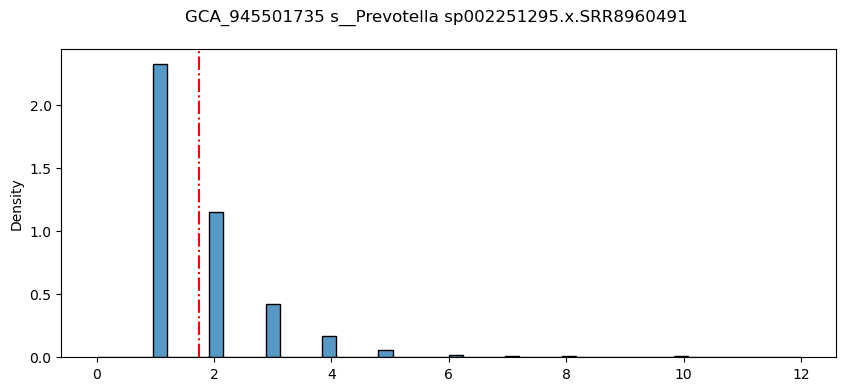

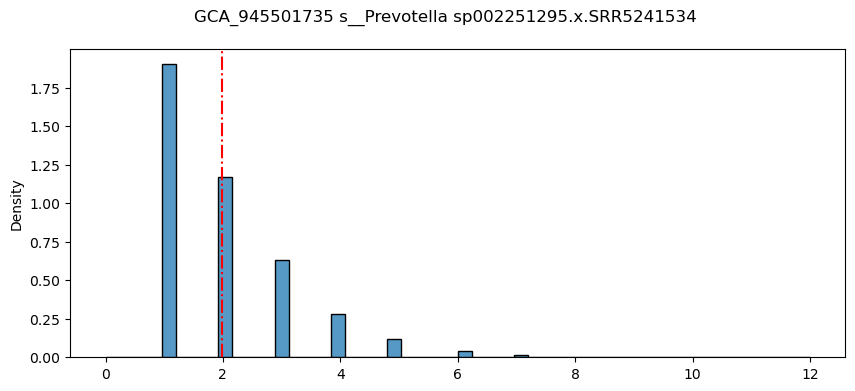

BICS: 4 [(4, 4086.57), (3, 4119.73), (5, 4140.28), (2, 4253.1), (1, 4818.97)]
0: 3.5 0.282 0.423
*1: 5.7 0.379 2.629
2: 16.1 0.022 59.360
3: 1.5 0.316 0.283


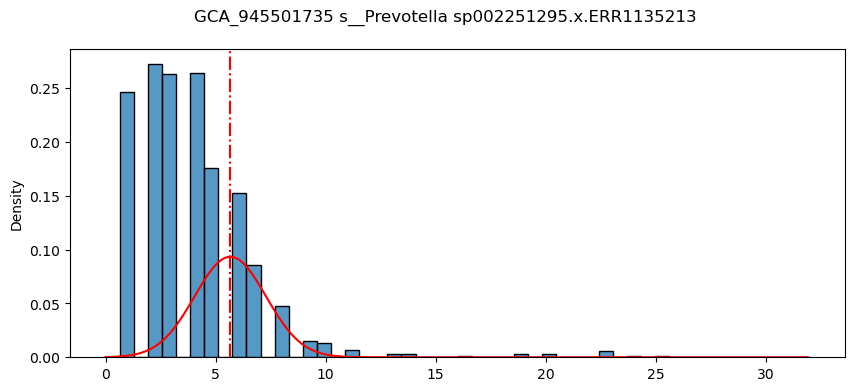

BICS: 5 [(5, 9609.26), (4, 9734.74), (3, 9773.82), (2, 9787.56), (1, 10859.26)]
0: 7.3 0.378 10.518
1: 1.5 0.316 0.468
2: 12.8 0.162 4.576
*3: 17.3 0.119 6.886
4: 19.1 0.025 74.157


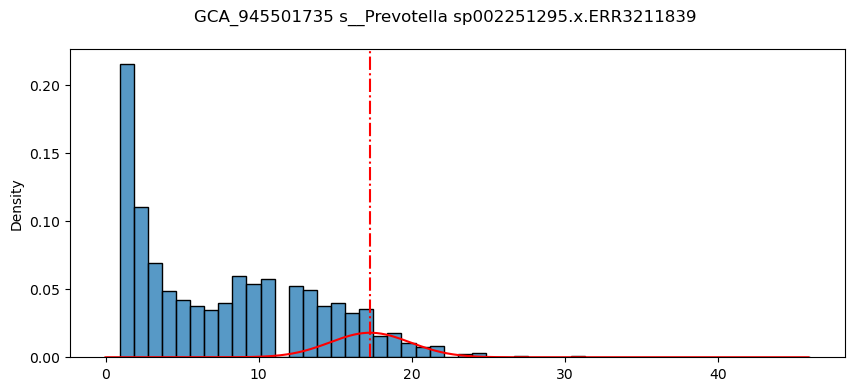

BICS: 5 [(5, 4748.22), (4, 9594.71), (2, 9658.93), (3, 9668.28), (1, 10929.43)]
0: 1.5 0.338 0.518
*1: 15.6 0.247 8.373
2: 7.9 0.328 14.488
3: 37.7 0.003 210.845
4: 20.8 0.084 11.253


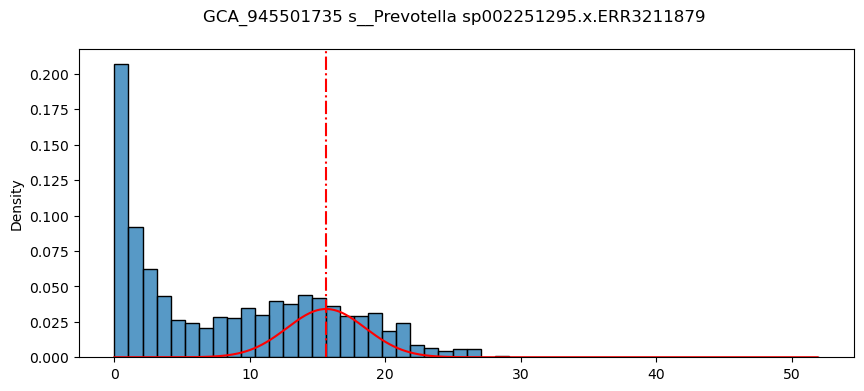

BICS: 5 [(5, 9853.76), (4, 10025.55), (3, 10109.61), (2, 10119.11), (1, 11495.25)]
0: 4.2 0.228 3.546
*1: 18.8 0.196 18.168
2: 13.1 0.291 11.246
3: 1.3 0.280 0.215
4: 36.0 0.005 279.239


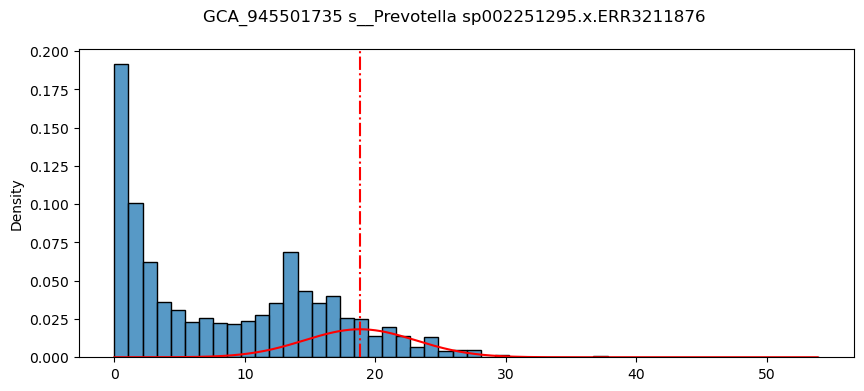

BICS: 3 [(3, 9445.45), (4, 9460.9), (5, 9482.93), (2, 9593.28), (1, 10399.14)]
0: 2.2 0.289 1.446
1: 32.2 0.040 404.601
*2: 20.0 0.671 59.744


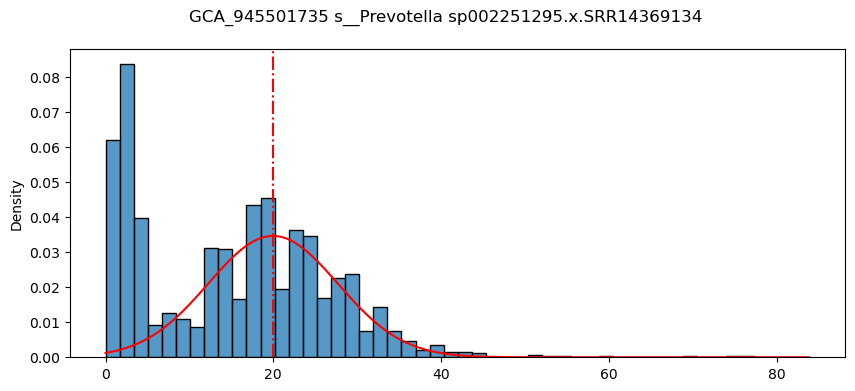

BICS: 5 [(5, 12482.48), (4, 12505.46), (3, 12819.37), (2, 12862.76), (1, 14829.51)]
*0: 30.8 0.232 29.819
1: 5.5 0.234 6.848
2: 1.6 0.294 0.552
3: 21.9 0.211 40.209
4: 31.2 0.029 288.526


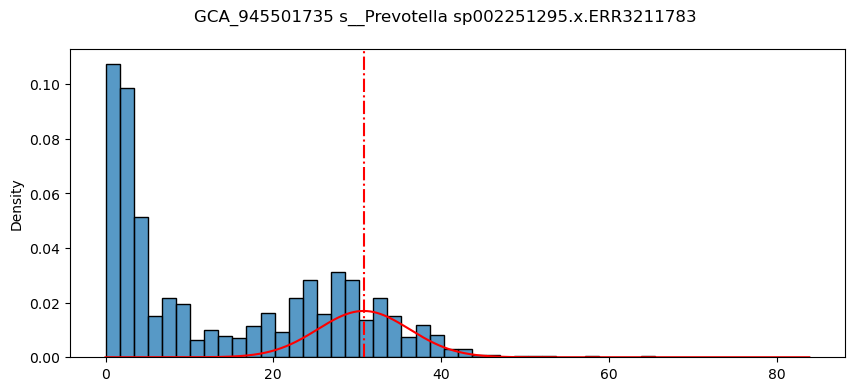

BICS: 5 [(5, 11225.69), (4, 11242.01), (3, 11284.68), (2, 11345.41), (1, 12676.1)]
0: 6.2 0.169 9.029
*1: 45.2 0.323 65.563
2: 1.7 0.212 0.558
3: 69.9 0.012 1034.668
4: 32.7 0.284 70.864


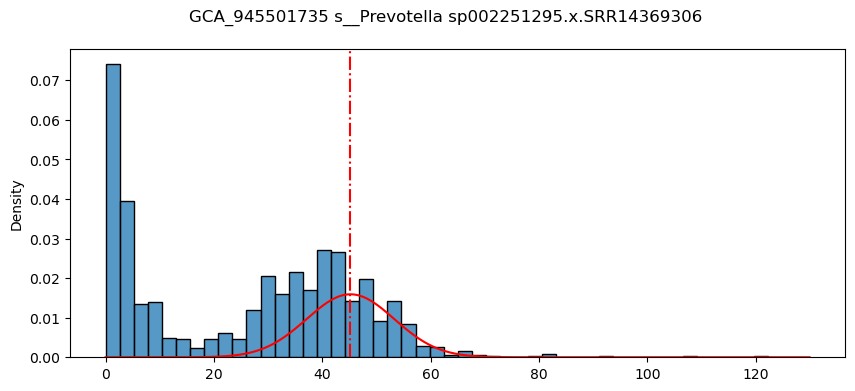

BICS: 3 [(3, 12297.0), (4, 12340.16), (5, 12363.59), (2, 12444.54), (1, 13909.99)]
*0: 45.6 0.439 72.958
1: 3.8 0.380 9.808
2: 42.1 0.181 522.152


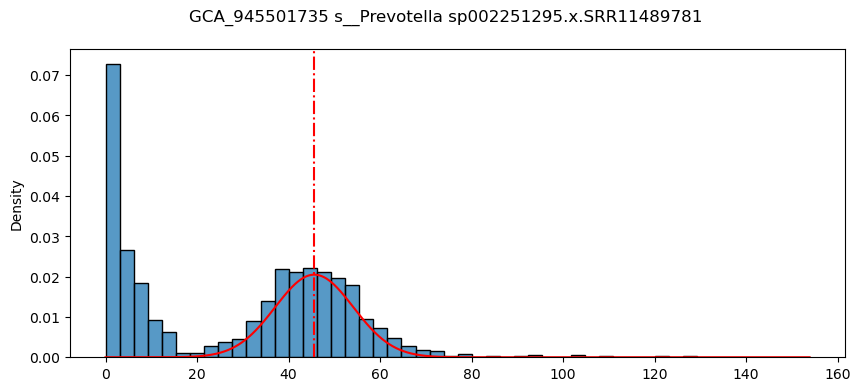

In [6]:
SS='GCA_945501735 s__Prevotella sp002251295'

METAGS=[
 'SRR8960491',
 'SRR5241534',
 'ERR1135213',
 'ERR3211839',
 'ERR3211879',
 'ERR3211876',
 'SRR14369134',
 'ERR3211783',
 'SRR14369306',
 'SRR11489781']

#plot_covhist_panel(SS, METAGS, ymax=100)

for i in METAGS:
    load_fit_plot_isect(SS, i)

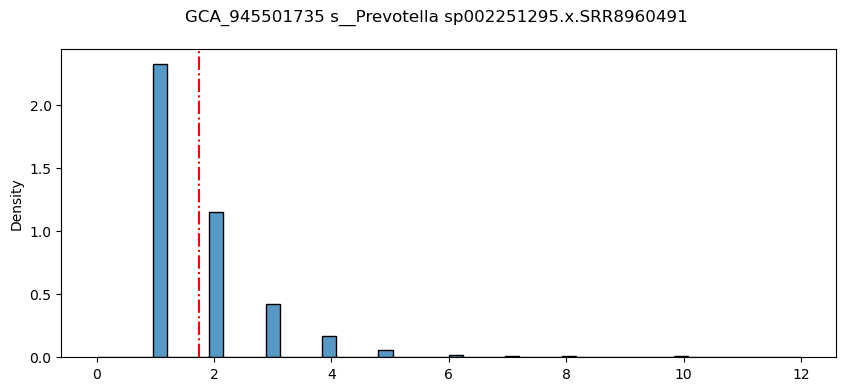

In [7]:
SS='GCA_945501735 s__Prevotella sp002251295'
load_fit_plot_isect(SS, 'SRR8960491')

## Misc prevotella IGNORE

In [8]:
SS='GCA_945501735 s__Prevotella sp002251295'

METAGS=[
 'SRR8960491',
 'SRR5241534',
 'ERR1135213',
 'ERR3211839',
 'ERR3211879',
 'ERR3211876',
 'SRR14369134',
 'ERR3211783',
 'SRR14369306',
 'SRR11489781']

#plot_covhist_panel(SS, METAGS, ymax=100)

for i in METAGS:
    filename = f'../outputs.isect/3216_isect.d/{SS} singlehash.x.{i}.sig.zip'
    print(load_fit_isect(filename))

('SRR8960491', 's__Prevotella sp002251295', 1.3103867245022343, 0.7716318654055586)
('SRR5241534', 's__Prevotella sp002251295', 1.3306694610761247, 0.6332931783492285)
('ERR1135213', 's__Prevotella sp002251295', 3.615470464953081, 0.9557608708265979)
('ERR3211839', 's__Prevotella sp002251295', 10.806530250491825, 0.680833928687434)
('ERR3211879', 's__Prevotella sp002251295', 12.793304136643183, 0.644903191934401)
('ERR3211876', 's__Prevotella sp002251295', 13.16376836997501, 0.6388821796093369)
('SRR14369134', 's__Prevotella sp002251295', 20.35375184087731, 0.7241634563711099)
('ERR3211783', 's__Prevotella sp002251295', 23.88795191443406, 0.558553575117516)
('SRR14369306', 's__Prevotella sp002251295', 37.85991539301757, 0.6638205737186494)
('SRR11489781', 's__Prevotella sp002251295', 45.22406793023974, 0.6092714647906161)


## Load lacto kmer coverage estimates

In [9]:
lacto_kmer_df = pl.read_csv('../outputs.isect/s__Lactobacillus amylovorus.isect.abund.csv')

## Plot some high abundance ones

In [10]:
lacto_kmer_df = lacto_kmer_df.sort('abund', descending=True).drop_nans()
lacto_kmer_df

species,metag,abund,method
str,str,f64,str
"""s__Lactobacillus amylovorus""","""SRR17241521""",2851.924286,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR11185260""",2633.922006,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR11185246""",2605.925577,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR17241521""",2471.667715,"""gmm"""
"""s__Lactobacillus amylovorus""","""SRR17241521""",2471.667715,"""composite_k"""
…,…,…,…
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""covcurve_round2"""
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""composite_k"""
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""composite"""


BICS: 5 [(5, 5900.57), (4, 6006.43), (3, 6026.79), (2, 6847.34), (1, 10999.33)]
0: 1.4 0.429 0.370
1: 2395.8 0.021 8365.262
2: 12.5 0.311 99.993
*3: 2461.6 0.161 666743.555
4: 181.9 0.078 19202.330


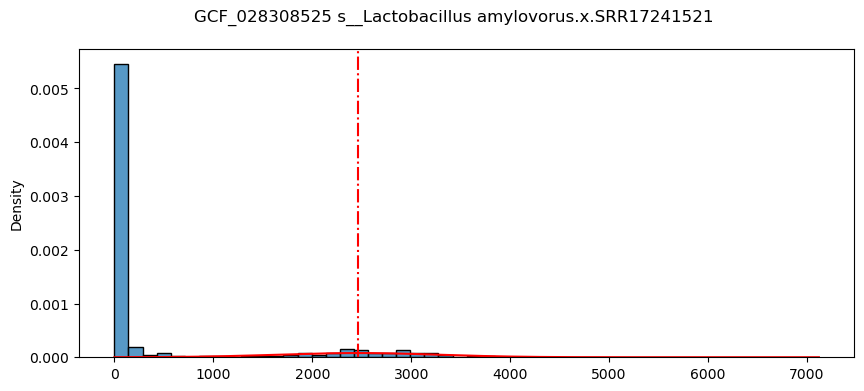

BICS: 4 [(4, 6123.35), (5, 6129.47), (3, 6137.28), (2, 6713.09), (1, 9912.07)]
0: 1.9 0.488 1.492
1: 1365.5 0.159 485087.759
*2: 2282.7 0.115 93195.060
3: 49.6 0.239 1817.284


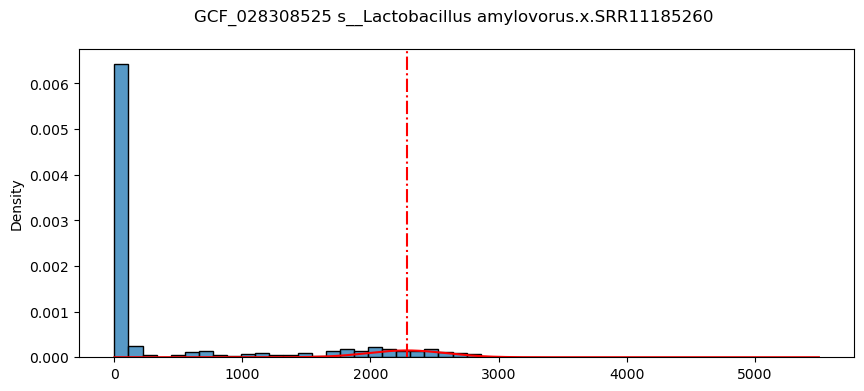

BICS: 3 [(3, 6882.13), (4, 6899.21), (2, 7324.65), (5, 9075.48), (1, 11991.7)]
0: 3.3 0.655 9.964
*1: 2224.5 0.168 178918.367
2: 80.8 0.177 10658.508


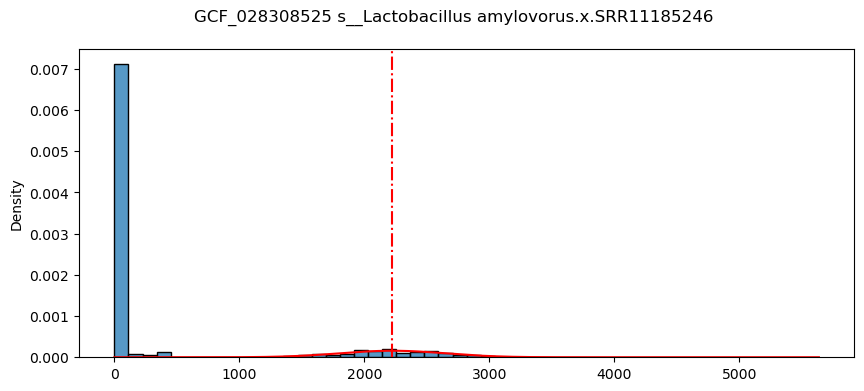

BICS: 5 [(5, 5900.48), (4, 6006.51), (3, 6026.9), (2, 6847.34), (1, 10999.33)]
0: 1.4 0.429 0.372
*1: 2466.7 0.161 657756.303
2: 2395.0 0.021 8279.328
3: 12.6 0.310 100.991
4: 184.6 0.078 19776.722


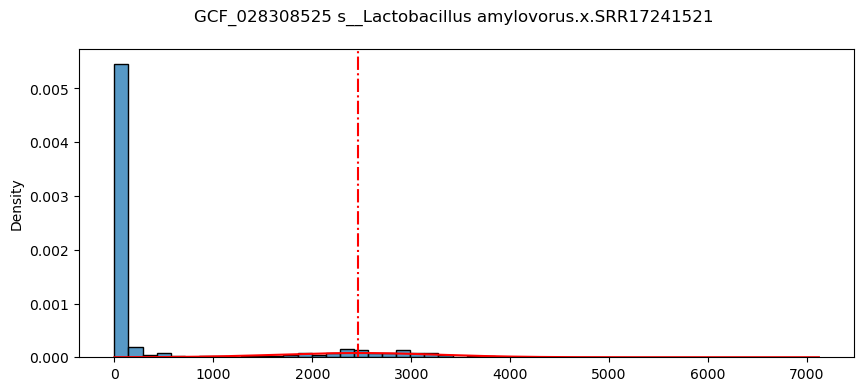

BICS: 5 [(5, 5925.42), (4, 6006.51), (3, 6026.79), (2, 6847.34), (1, 10999.33)]
0: 1.4 0.429 0.372
1: 2395.1 0.021 8294.686
*2: 2467.4 0.161 656587.523
3: 12.6 0.310 101.070
4: 184.9 0.078 19862.749


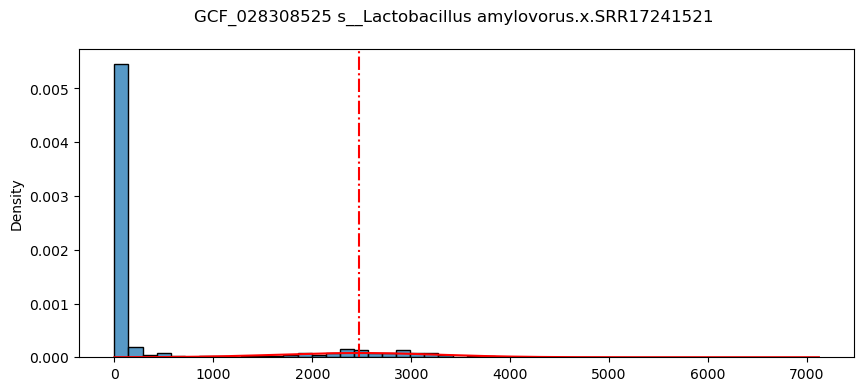

BICS: 2 [(2, 5000.94), (3, 5021.25), (4, 5028.28), (5, 5050.25), (1, 7723.4)]
*0: 2045.9 0.276 131998.999
1: 8.4 0.724 158.020


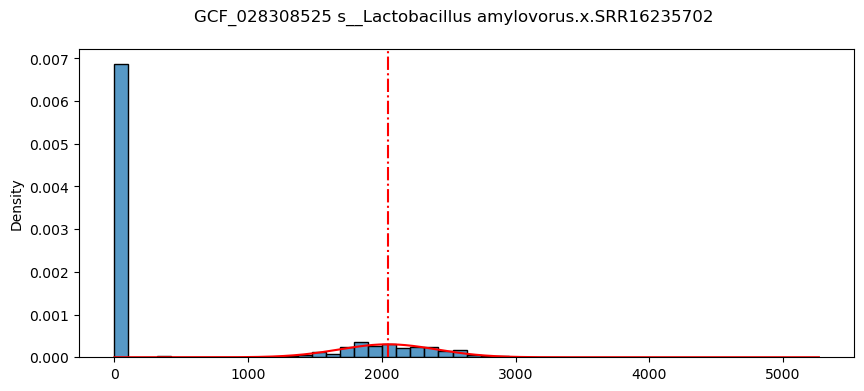

BICS: 4 [(4, 6123.35), (5, 6131.83), (3, 6137.28), (2, 6713.09), (1, 9912.07)]
0: 1.9 0.488 1.492
1: 1365.5 0.159 485087.759
2: 49.6 0.239 1817.284
*3: 2282.7 0.115 93195.060


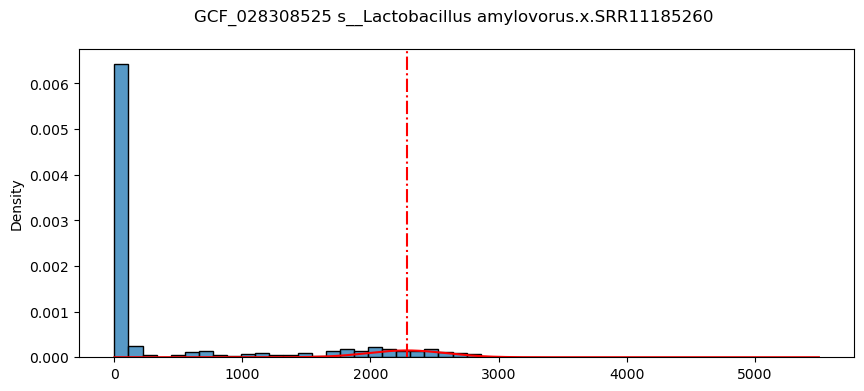

BICS: 4 [(4, 6123.35), (5, 6131.83), (3, 6137.28), (2, 6713.09), (1, 9912.07)]
0: 1.9 0.488 1.492
*1: 2282.7 0.115 93195.060
2: 1365.5 0.159 485087.759
3: 49.6 0.239 1817.284


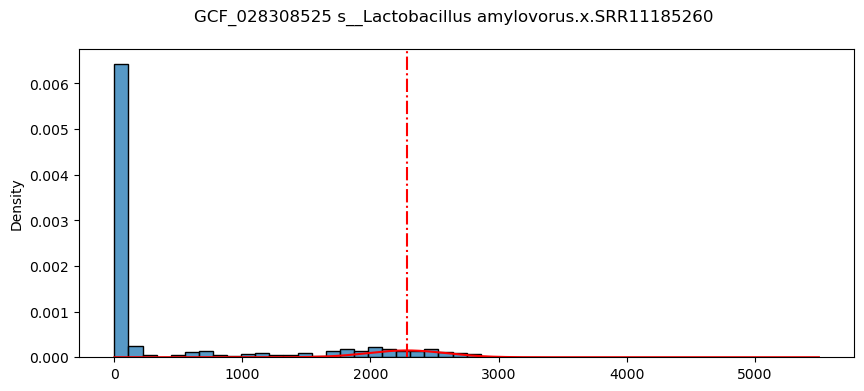

BICS: 3 [(3, 6882.23), (4, 6894.51), (2, 7324.65), (5, 9075.48), (1, 11991.7)]
0: 4.0 0.698 17.786
*1: 1270.5 0.300 1177277.545
2: 4489.0 0.001 0.000


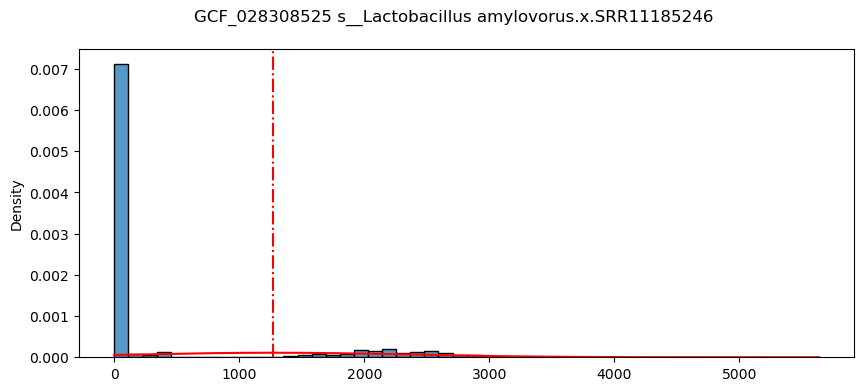

BICS: 3 [(3, 6882.13), (4, 6902.21), (2, 7324.65), (5, 9075.34), (1, 11991.7)]
0: 4489.0 0.001 0.000
1: 4.0 0.698 17.786
*2: 1270.5 0.300 1177277.545


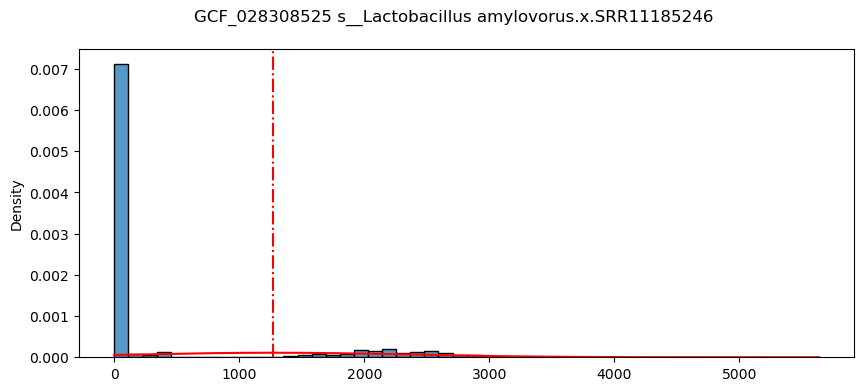

In [11]:
for metag in lacto_kmer_df.head(10)['metag']:
    load_fit_plot_isect('GCF_028308525 s__Lactobacillus amylovorus', metag)

In [12]:
lacto_kmer_df

species,metag,abund,method
str,str,f64,str
"""s__Lactobacillus amylovorus""","""SRR17241521""",2851.924286,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR11185260""",2633.922006,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR11185246""",2605.925577,"""composite"""
"""s__Lactobacillus amylovorus""","""SRR17241521""",2471.667715,"""gmm"""
"""s__Lactobacillus amylovorus""","""SRR17241521""",2471.667715,"""composite_k"""
…,…,…,…
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""covcurve_round2"""
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""composite_k"""
"""s__Lactobacillus amylovorus""","""ERR3212035""",0.0,"""composite"""


In [13]:
depth_df = pl.read_csv('../mapping-depth.csv')

FileNotFoundError: No such file or directory (os error 2): ../mapping-depth.csv

In [ ]:
lacto_depth_df = depth_df.filter(pl.col('gene') == 'AtH2023_SRR8960431_MAG03_43_3')

In [ ]:
lacto_depth_df

In [ ]:
lacto_all_df = lacto_depth_df.join(lacto_kmer_df, on='metag')
lacto_all_df

In [ ]:
MAX=1000
plt.plot(lacto_all_df['depth_all'], lacto_all_df['abund'], '*')
plt.plot([0, MAX], [0, MAX], '--')
plt.xlim(0, MAX)
plt.ylim(0, MAX)
plt.xlabel('mapping depth')
plt.ylabel('kmer depth')
plt.title('s__Lactobacillus amylovorus')

## Try out prevotella

In [ ]:
depth_df

In [ ]:
prevotella_kmer_df = pl.read_csv('../outputs.isect/s__Prevotella sp002251295.isect.abund.csv')

In [ ]:
prevotella_depth_df = depth_df.filter(pl.col('gene') == 'AtH2023_ERR3211937_MAG3_16_9')

In [ ]:
prevotella_all_df = prevotella_depth_df.join(prevotella_kmer_df, on='metag')

In [ ]:
MAX=400
plt.plot(prevotella_all_df['depth_all'], prevotella_all_df['abund'], '*')
plt.plot([0, MAX], [0, MAX], '--')
plt.xlim(0, MAX)
plt.ylim(0, MAX)
plt.xlabel('mapping depth')
plt.ylabel('kmer depth')
plt.title('s__Prevotella sp002251295')

## Plot all of the ones for which we have anchor genes?

In [ ]:
new_genes_df = pl.read_csv('../new_genes_df.csv')

In [ ]:
combo_genes_df = depth_df.join(new_genes_df.filter(pl.col('anchor') == 1), left_on='gene', right_on='gene_name', how='inner', coalesce=True)

In [ ]:
combo_kmer_df = pl.read_csv('../outputs.isect/*.csv')

In [ ]:
all_df = combo_genes_df.join(combo_kmer_df, on=['metag', 'species'], how='inner')

In [ ]:
for species in all_df['species'].unique():
    xx_df = all_df.filter(pl.col('species') == species)

    depths = list(sorted(xx_df['depth_all']))
    MAX = depths[int(len(depths) * 0.9)]

    if MAX < 20:
        print('SKIPPING:', species)
        continue
    
    plt.plot(xx_df['depth_all'], xx_df['abund'], '*')
    plt.plot([0, MAX], [0, MAX], '--')
    plt.xlim(0, MAX)
    plt.ylim(0, MAX)
    plt.xlabel('mapping depth')
    plt.ylabel('kmer depth')
    plt.title(species)
    plt.show()